AVISO – estudios sin tier codificado: ['S04']
Archivos guardados en: /Users/joanpau/Documents/00_Inbox/SLR - Results Points/Images/fig_boundary_overview70.{pdf,png,svg}

Tier por pilar (n):
 Tier            N/A  NR  T0  T1  T2  T3
Pillar_5                               
All studies       1   8   4  32  17   8
Avoid             0   0   0   1   0   0
Shift             0   2   0   3   3   3
Improve           0   1   1  11   5   3
Dual-pillar       0   3   1   6   3   1
Integrated ASI    1   2   2  11   6   1

Estudios que contabilizan cada etapa: {'T0': 61, 'T1': 57, 'T2': 25, 'T3': 8, 'EoL': 9}


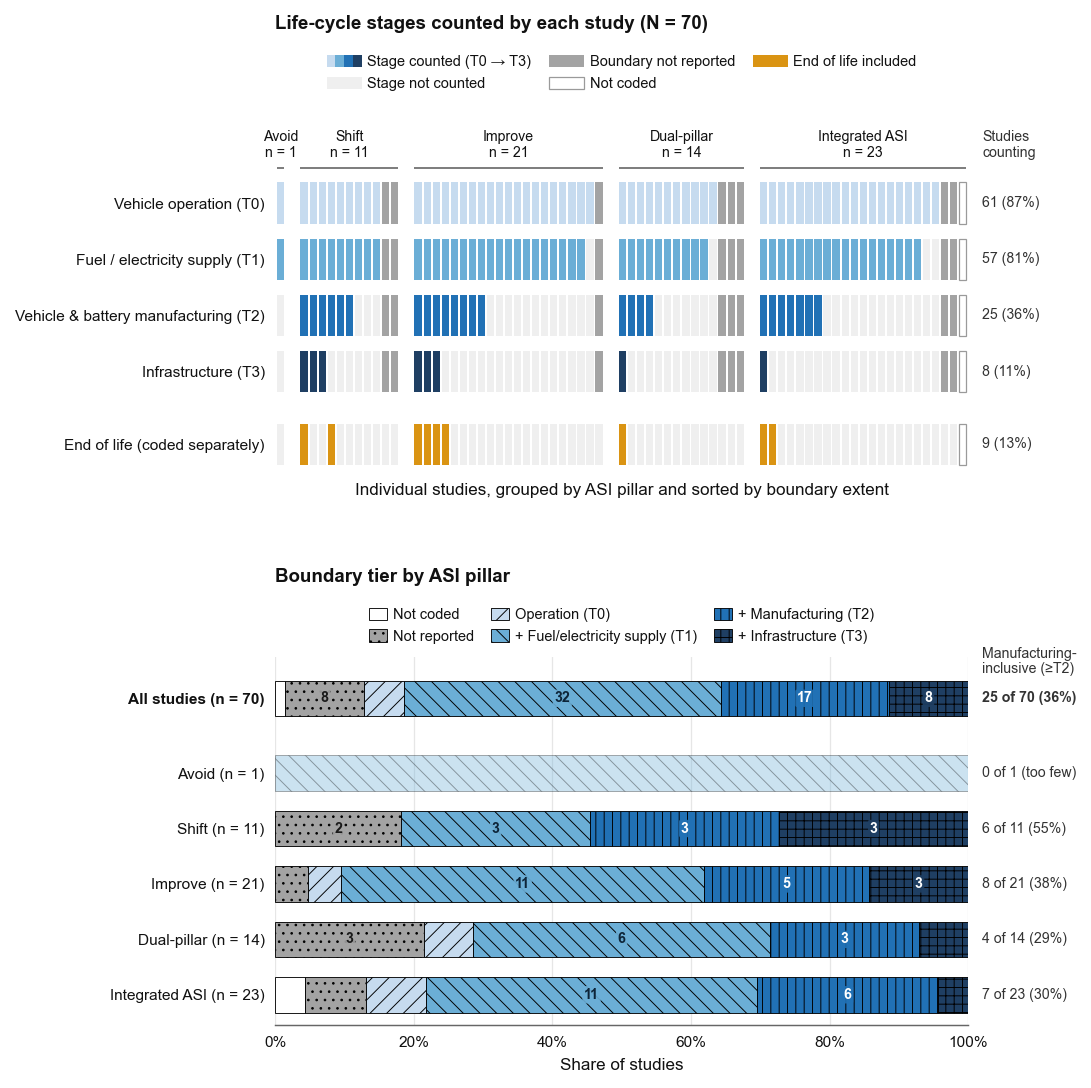

In [7]:
# %% [FIGURA 3.2 – WHAT STUDIES COUNT] Matriz de etapas del ciclo de vida por estudio + alcance por pilar ASI (N = 70)
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import Patch, Rectangle
from matplotlib.legend_handler import HandlerTuple

# ==============================================================================
# 0. RUTAS Y PARÁMETROS
# ==============================================================================
DARK_MODE = False
FS = 1.0                      # Escala de TODAS las fuentes
FIGSIZE = (8.4, 7.4)          # 8.4 in de ancho -> \textwidth (factor 0.75), como la figura del evidence base
MIN_N_ROW = 3                 # filas con n < 3 se atenúan y no se porcentúan

INFILE = Path("/Users/joanpau/Documents/00_Inbox/SLR - Results Points/SLR Extraction Sheet.xlsx")
if not INFILE.exists():
    raise FileNotFoundError(f"No se encontró el archivo en: {INFILE}")
OUTDIR = INFILE.parent / "Images"
OUTDIR.mkdir(exist_ok=True)

df = pd.read_excel(INFILE, sheet_name="Extraction").dropna(subset=["ID"])
df["ID"] = df["ID"].astype(str).str.strip()
N_TOTAL = len(df)

# --- Pilares ASI (5 grupos, mismos que en la figura del evidence base) ---
ASI_5_ORDER = ["Avoid", "Shift", "Improve", "Dual-pillar", "Integrated ASI"]
PILLAR_5_MAP = {"A": "Avoid", "S": "Shift", "I": "Improve",
                "A+S": "Dual-pillar", "A+I": "Dual-pillar", "S+I": "Dual-pillar",
                "A+S+I": "Integrated ASI"}
df["Pillar_5"] = df["Pillar"].astype(str).str.strip().map(PILLAR_5_MAP)

# --- Tier de frontera (acumulativo: T0 ⊂ T1 ⊂ T2 ⊂ T3) ---
# Celda vacía -> "N/A" (no codificado). S04 está en blanco porque no cuantifica GHG.
TIER_MAP = {"T0": "T0", "T1": "T1", "T2": "T2", "T3": "T3",
            "Not reported": "NR", "NR": "NR", "N/A": "N/A", "nan": "N/A", "": "N/A"}
# fillna("") antes de astype(str): en pandas >= 3 las celdas vacías siguen siendo NaN tras astype(str)
df["Tier"] = df["Boundary tier"].fillna("").astype(str).str.strip().map(TIER_MAP)
df["EoL"] = df["End of life"].fillna("").astype(str).str.strip().str.upper().eq("Y")

assert df["Pillar_5"].isna().sum() == 0, df.loc[df["Pillar_5"].isna(), "ID"].tolist()
assert df["Tier"].isna().sum() == 0, df.loc[df["Tier"].isna(), "Boundary tier"].tolist()
if (df["Tier"] == "N/A").any():
    print("AVISO – estudios sin tier codificado:", df.loc[df["Tier"] == "N/A", "ID"].tolist())

TIER_ORDER = ["N/A", "NR", "T0", "T1", "T2", "T3"]           # de menos a más alcance
TIER_RANK = {t: i for i, t in enumerate(TIER_ORDER)}
STAGE_TIERS = ["T0", "T1", "T2", "T3"]                        # etapa que añade cada tier

# ==============================================================================
# 1. PALETA Y TIPOGRAFÍA (misma familia que el resto del paper)
# ==============================================================================
BG_COL    = "#000000" if DARK_MODE else "#FFFFFF"
FG_COL    = "#FFFFFF" if DARK_MODE else "#111111"
SUB_COL   = "#D9D9D9" if DARK_MODE else "#333333"
EDGE_COL  = "#FFFFFF" if DARK_MODE else "#000000"
GRID_COL  = "#222222" if DARK_MODE else "0.90"
SPINE_COL = "#888888" if DARK_MODE else "0.40"
EMPTY_COL = "#1c1c1c" if DARK_MODE else "#efefef"            # etapa no contabilizada
EOL_COL   = "#f2be54" if DARK_MODE else "#da9413"            # fin de vida (dimensión aparte)
NA_EDGE   = "#777777" if DARK_MODE else "#9a9a9a"            # contorno de "no codificado"

TIER_COLORS = {"N/A": BG_COL, "NR": "#a3a3a3",
               "T0": "#c6dbef", "T1": "#6baed6", "T2": "#2171b5",
               "T3": "#2b5c8f" if DARK_MODE else "#1f3f63"}
TIER_HATCH = {"N/A": "", "NR": "...", "T0": "///", "T1": "\\\\\\", "T2": "|||", "T3": "+++"}
TIER_TEXT = {"N/A": "#4d4d4d", "NR": "#1a1a1a", "T0": "#1f3f63", "T1": "#0d2438",
             "T2": "#ffffff", "T3": "#ffffff"}
TIER_LABELS = {"N/A": "Not coded", "NR": "Not reported", "T0": "Operation (T0)",
               "T1": "+ Fuel/electricity supply (T1)", "T2": "+ Manufacturing (T2)",
               "T3": "+ Infrastructure (T3)"}
STAGE_LABELS = {"T0": "Vehicle operation (T0)",
                "T1": "Fuel / electricity supply (T1)",
                "T2": "Vehicle & battery manufacturing (T2)",
                "T3": "Infrastructure (T3)",
                "EoL": "End of life (coded separately)"}

F_TITLE, F_LABEL, F_TICK, F_LEG, F_ANN = 9.0 * FS, 8.2 * FS, 7.4 * FS, 7.0 * FS, 6.8 * FS

# Arial primero: en macOS "Helvetica.ttc" no expone la negrita a matplotlib (los títulos
# salían en regular). Arial es métricamente equivalente y sí tiene negrita real.
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": F_TICK, "axes.labelsize": F_LABEL, "axes.titlesize": F_TITLE,
    "xtick.labelsize": F_TICK, "ytick.labelsize": F_TICK, "legend.fontsize": F_LEG,
    "axes.linewidth": 0.7, "hatch.linewidth": 0.45, "hatch.color": EDGE_COL,
    "figure.facecolor": BG_COL, "axes.facecolor": BG_COL, "savefig.facecolor": BG_COL,
    "text.color": FG_COL, "axes.labelcolor": FG_COL, "xtick.color": FG_COL, "ytick.color": FG_COL,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})

# ==============================================================================
# 2. MAQUETACIÓN (mismo sistema que la figura del evidence base):
#    título a la izquierda del panel (set_title, loc="left") y leyenda justo encima del gráfico
# ==============================================================================
LEGEND_ALIGN = "center"        # "center" = leyenda centrada sobre el gráfico | "left" = alineada a su borde izquierdo
TITLE_PAD = 36 * FS            # espacio entre el gráfico y el título (deja sitio a la leyenda de 2 filas)

fig = plt.figure(figsize=FIGSIZE, dpi=150, facecolor=BG_COL)
gs = gridspec.GridSpec(2, 1, figure=fig, height_ratios=[1.0, 1.0], hspace=0.50,
                       left=0.31, right=0.86, top=0.90, bottom=0.07)
ax_m = fig.add_subplot(gs[0])
ax_r = fig.add_subplot(gs[1])

def panel_title(ax, text):
    ax.set_title(text, fontsize=F_TITLE, fontweight="bold", pad=TITLE_PAD, loc="left",
                 color=FG_COL)

def top_legend(ax, handles, labels, ncol, handlelength=1.2):
    loc, anchor = (("lower center", (0.5, 1.02)) if LEGEND_ALIGN == "center"
                   else ("lower left", (0.0, 1.02)))
    leg = ax.legend(handles, labels, ncol=ncol, frameon=False, fontsize=F_LEG,
                    handlelength=handlelength, handleheight=0.9, columnspacing=1.2,
                    handletextpad=0.4, loc=loc, bbox_to_anchor=anchor, borderaxespad=0,
                    handler_map={tuple: HandlerTuple(ndivide=None, pad=0.0)})
    for txt in leg.get_texts():
        txt.set_color(FG_COL)
    return leg

# ------------------------------------------------------------------------------
# PANEL SUPERIOR: etapas del ciclo de vida que contabiliza cada estudio
# ------------------------------------------------------------------------------
GROUP_GAP = 1.6
W, H = 0.80, 0.74                                   # tamaño de la celda (en unidades de datos)
ROW_Y = {"T0": 4.0, "T1": 3.0, "T2": 2.0, "T3": 1.0, "EoL": -0.3}
Y_BR = ROW_Y["T0"] + 0.62                           # corchetes de grupo (dentro del panel)

df_sorted = (df.assign(_g=df["Pillar_5"].map({p: i for i, p in enumerate(ASI_5_ORDER)}),
                       _t=-df["Tier"].map(TIER_RANK), _e=~df["EoL"])
               .sort_values(["_g", "_t", "_e", "ID"]))

x, xpos, group_span = 0.0, [], {}
for g in ASI_5_ORDER:
    n_g = int((df_sorted["Pillar_5"] == g).sum())
    x0 = x
    xpos.extend(x0 + np.arange(n_g))
    x += n_g
    group_span[g] = (x0, x - 1.0, n_g)
    x += GROUP_GAP
x_max = x - GROUP_GAP - 1.0
df_sorted = df_sorted.assign(_x=xpos)

def tile(ax, xc, yc, fc, ec="none"):
    ax.add_patch(Rectangle((xc - W / 2, yc - H / 2), W, H, facecolor=fc, edgecolor=ec,
                           linewidth=0.6 if ec != "none" else 0))

for _, r in df_sorted.iterrows():
    rank = TIER_RANK[r["Tier"]]
    for st in STAGE_TIERS:
        if r["Tier"] == "NR":
            tile(ax_m, r["_x"], ROW_Y[st], TIER_COLORS["NR"])
        elif r["Tier"] == "N/A":
            tile(ax_m, r["_x"], ROW_Y[st], BG_COL, NA_EDGE)
        elif TIER_RANK[st] <= rank:
            tile(ax_m, r["_x"], ROW_Y[st], TIER_COLORS[st])
        else:
            tile(ax_m, r["_x"], ROW_Y[st], EMPTY_COL)
    if r["Tier"] == "N/A":
        tile(ax_m, r["_x"], ROW_Y["EoL"], BG_COL, NA_EDGE)
    else:
        tile(ax_m, r["_x"], ROW_Y["EoL"], EOL_COL if r["EoL"] else EMPTY_COL)

# Corchetes y etiquetas de grupo (pilar), dentro del área del panel
for g, (x0, x1, n) in group_span.items():
    ax_m.plot([x0 - 0.40, x1 + 0.40], [Y_BR, Y_BR], color=SPINE_COL, lw=0.8,
              solid_capstyle="butt")
    ax_m.text((x0 + x1) / 2, Y_BR + 0.16, f"{g}\nn = {n}", ha="center", va="bottom",
              fontsize=F_ANN, color=FG_COL, linespacing=1.1)

ax_m.set_xlim(-0.6, x_max + 0.6)
ax_m.set_ylim(ROW_Y["EoL"] - 0.5, Y_BR + 1.15)
rows_m = ["T0", "T1", "T2", "T3", "EoL"]
ax_m.set_yticks([ROW_Y[k] for k in rows_m])
ax_m.set_yticklabels([STAGE_LABELS[k] for k in rows_m])
ax_m.set_xticks([])
ax_m.tick_params(length=0, pad=5)
for s in ax_m.spines.values():
    s.set_visible(False)
ax_m.set_xlabel("Individual studies, grouped by ASI pillar and sorted by boundary extent",
                fontsize=F_LABEL, labelpad=5)

# Columna derecha: estudios que contabilizan cada etapa
tier_rank_s = df["Tier"].map(TIER_RANK)
counted = {st: int(((tier_rank_s >= TIER_RANK[st]) & df["Tier"].isin(STAGE_TIERS)).sum())
           for st in STAGE_TIERS}
counted["EoL"] = int(df["EoL"].sum())
X_COL = 1.02                                         # columna derecha (fracción del eje), común a ambos paneles
trans_m = ax_m.get_yaxis_transform()
ax_m.text(X_COL, Y_BR + 0.16, "Studies\ncounting", transform=trans_m, ha="left", va="bottom",
          fontsize=F_ANN, color=SUB_COL, linespacing=1.1, clip_on=False)
for key in rows_m:
    n = counted[key]
    ax_m.text(X_COL, ROW_Y[key], f"{n} ({100 * n / N_TOTAL:.0f}%)", transform=trans_m,
              ha="left", va="center", fontsize=F_ANN, color=SUB_COL, clip_on=False)

panel_title(ax_m, f"Life-cycle stages counted by each study (N = {N_TOTAL})")
ramp = tuple(Patch(facecolor=TIER_COLORS[t], edgecolor="none") for t in STAGE_TIERS)
top_legend(ax_m,
           [ramp,
            Patch(facecolor=EMPTY_COL, edgecolor="none"),
            Patch(facecolor=TIER_COLORS["NR"], edgecolor="none"),
            Patch(facecolor=BG_COL, edgecolor=NA_EDGE, linewidth=0.6),
            Patch(facecolor=EOL_COL, edgecolor="none")],
           ["Stage counted (T0 → T3)", "Stage not counted", "Boundary not reported",
            "Not coded", "End of life included"],
           ncol=3, handlelength=2.4)

# ------------------------------------------------------------------------------
# PANEL INFERIOR: distribución del tier por pilar (100 %) + cuota que incluye fabricación
# ------------------------------------------------------------------------------
rows = ["All studies"] + ASI_5_ORDER
ct = (pd.crosstab(df["Pillar_5"], df["Tier"])
        .reindex(index=ASI_5_ORDER, columns=TIER_ORDER, fill_value=0))
ct.loc["All studies"] = ct.sum()
ct = ct.loc[rows]
n_row = ct.sum(axis=1)
share = ct.div(n_row, axis=0) * 100

y_r = np.arange(len(rows))[::-1].astype(float)
y_r[0] += 0.35                                         # separa "All studies" del resto
left = np.zeros(len(rows))
for t in TIER_ORDER:
    vals = share[t].values
    for yi, l, v, c, r in zip(y_r, left, vals, ct[t].values, rows):
        if v == 0:
            continue
        small_n = n_row[r] < MIN_N_ROW
        ax_r.barh(yi, v, left=l, height=0.64, color=TIER_COLORS[t], edgecolor=EDGE_COL,
                  linewidth=0.42, hatch=TIER_HATCH[t], zorder=3, alpha=0.35 if small_n else 1)
        if v >= 9 and not small_n:
            ax_r.text(l + v / 2, yi, str(c), ha="center", va="center", fontsize=F_ANN,
                      fontweight="bold", color=TIER_TEXT[t], zorder=4,
                      bbox=dict(boxstyle="round,pad=0.12", facecolor=TIER_COLORS[t],
                                edgecolor="none", alpha=0.9))
    left += vals

ax_r.set_yticks(y_r)
ax_r.set_yticklabels([f"{r} (n = {n_row[r]})" for r in rows])
for lbl in ax_r.get_yticklabels():
    if lbl.get_text().startswith("All"):
        lbl.set_fontweight("bold")
ax_r.set_ylim(y_r.min() - 0.55, y_r.max() + 0.75)
ax_r.set_xlim(0, 100)
ax_r.set_xticks(range(0, 101, 20))
ax_r.set_xticklabels([f"{v}%" for v in range(0, 101, 20)])
ax_r.set_xlabel("Share of studies", fontsize=F_LABEL)
ax_r.xaxis.grid(True, color=GRID_COL, linewidth=0.6, zorder=0)
ax_r.set_axisbelow(True)
for s in ["top", "right", "left"]:
    ax_r.spines[s].set_visible(False)
ax_r.spines["bottom"].set_color(SPINE_COL)
ax_r.tick_params(length=0, pad=5)

# Columna derecha: cuántos estudios llegan a fabricación (>= T2)
trans_r = ax_r.get_yaxis_transform()
ax_r.text(X_COL, y_r[0] + 0.40, "Manufacturing-\ninclusive (≥T2)", transform=trans_r,
          ha="left", va="bottom", fontsize=F_ANN, color=SUB_COL, linespacing=1.1, clip_on=False)
for yi, r in zip(y_r, rows):
    k = int(ct.loc[r, ["T2", "T3"]].sum())
    txt = (f"{k} of {n_row[r]} ({100 * k / n_row[r]:.0f}%)" if n_row[r] >= MIN_N_ROW
           else f"{k} of {n_row[r]} (too few)")
    ax_r.text(X_COL, yi, txt, transform=trans_r, ha="left", va="center", fontsize=F_ANN,
              color=SUB_COL, fontweight="bold" if r == "All studies" else "normal", clip_on=False)

panel_title(ax_r, "Boundary tier by ASI pillar")
top_legend(ax_r,
           [Patch(facecolor=TIER_COLORS[t], hatch=TIER_HATCH[t], edgecolor=EDGE_COL,
                  linewidth=0.42) for t in TIER_ORDER],
           [TIER_LABELS[t] for t in TIER_ORDER],
           ncol=3)

# ==============================================================================
# 3. EXPORTACIÓN Y CIFRAS PARA EL TEXTO
# ==============================================================================
stem = f"fig_boundary_overview{N_TOTAL}" + ("_dark" if DARK_MODE else "")
for ext in ["pdf", "png", "svg"]:
    fig.savefig(OUTDIR / f"{stem}.{ext}", dpi=600 if ext == "png" else 300,
                bbox_inches="tight", pad_inches=0.04, facecolor=BG_COL, edgecolor="none")
print(f"Archivos guardados en: {OUTDIR}/{stem}.{{pdf,png,svg}}")
print("\nTier por pilar (n):\n", ct.to_string())
print("\nEstudios que contabilizan cada etapa:", counted)
plt.show()

AVISO – estudios sin tier codificado: ['S04']
Archivos guardados en: /Users/joanpau/Documents/00_Inbox/SLR - Results Points/Images/fig_boundary_overview70.{pdf,png,svg}

Tier por pilar (n):
 Tier            N/A  NR  T0  T1  T2  T3
Pillar_5                               
All studies       1   8   4  32  17   8
Avoid             0   0   0   1   0   0
Shift             0   2   0   3   3   3
Improve           0   1   1  11   5   3
Dual-pillar       0   3   1   6   3   1
Integrated ASI    1   2   2  11   6   1

Estudios que contabilizan cada etapa: {'T0': 61, 'T1': 57, 'T2': 25, 'T3': 8, 'EoL': 9}


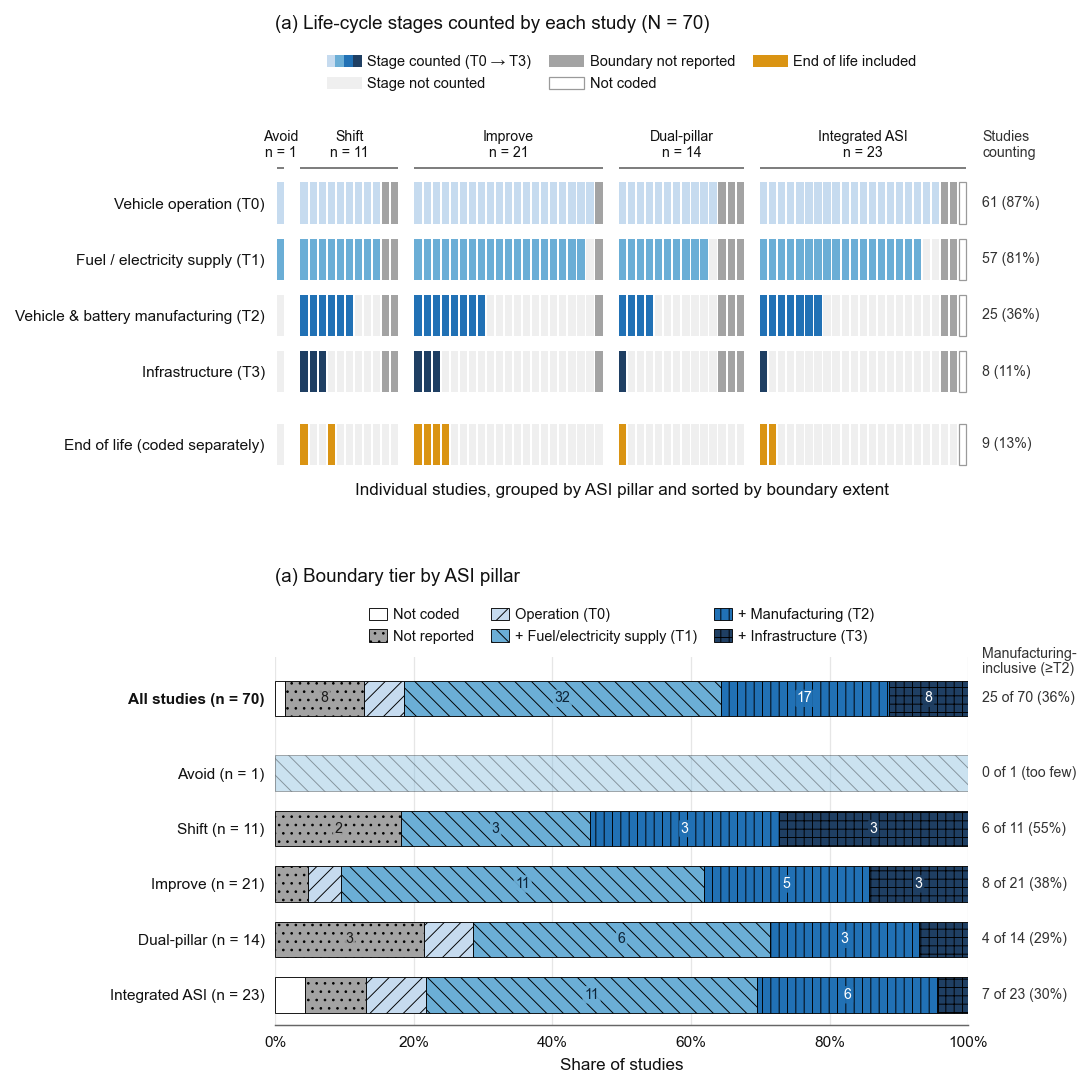

In [10]:
# %% [FIGURA 3.2 – WHAT STUDIES COUNT] Matriz de etapas del ciclo de vida por estudio + alcance por pilar ASI (N = 70)
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import Patch, Rectangle
from matplotlib.legend_handler import HandlerTuple

# ==============================================================================
# 0. RUTAS Y PARÁMETROS
# ==============================================================================
DARK_MODE = False
FS = 1.0                      # Escala de TODAS las fuentes
FIGSIZE = (8.4, 7.4)          # 8.4 in de ancho -> \textwidth (factor 0.75), como la figura del evidence base
MIN_N_ROW = 3                 # filas con n < 3 se atenúan y no se porcentúan

INFILE = Path("/Users/joanpau/Documents/00_Inbox/SLR - Results Points/SLR Extraction Sheet.xlsx")
if not INFILE.exists():
    raise FileNotFoundError(f"No se encontró el archivo en: {INFILE}")
OUTDIR = INFILE.parent / "Images"
OUTDIR.mkdir(exist_ok=True)

df = pd.read_excel(INFILE, sheet_name="Extraction").dropna(subset=["ID"])
df["ID"] = df["ID"].astype(str).str.strip()
N_TOTAL = len(df)

# --- Pilares ASI (5 grupos, mismos que en la figura del evidence base) ---
ASI_5_ORDER = ["Avoid", "Shift", "Improve", "Dual-pillar", "Integrated ASI"]
PILLAR_5_MAP = {"A": "Avoid", "S": "Shift", "I": "Improve",
                "A+S": "Dual-pillar", "A+I": "Dual-pillar", "S+I": "Dual-pillar",
                "A+S+I": "Integrated ASI"}
df["Pillar_5"] = df["Pillar"].astype(str).str.strip().map(PILLAR_5_MAP)

# --- Tier de frontera (acumulativo: T0 ⊂ T1 ⊂ T2 ⊂ T3) ---
# Celda vacía -> "N/A" (no codificado). S04 está en blanco porque no cuantifica GHG.
TIER_MAP = {"T0": "T0", "T1": "T1", "T2": "T2", "T3": "T3",
            "Not reported": "NR", "NR": "NR", "N/A": "N/A", "nan": "N/A", "": "N/A"}
# fillna("") antes de astype(str): en pandas >= 3 las celdas vacías siguen siendo NaN tras astype(str)
df["Tier"] = df["Boundary tier"].fillna("").astype(str).str.strip().map(TIER_MAP)
df["EoL"] = df["End of life"].fillna("").astype(str).str.strip().str.upper().eq("Y")

assert df["Pillar_5"].isna().sum() == 0, df.loc[df["Pillar_5"].isna(), "ID"].tolist()
assert df["Tier"].isna().sum() == 0, df.loc[df["Tier"].isna(), "Boundary tier"].tolist()
if (df["Tier"] == "N/A").any():
    print("AVISO – estudios sin tier codificado:", df.loc[df["Tier"] == "N/A", "ID"].tolist())

TIER_ORDER = ["N/A", "NR", "T0", "T1", "T2", "T3"]           # de menos a más alcance
TIER_RANK = {t: i for i, t in enumerate(TIER_ORDER)}
STAGE_TIERS = ["T0", "T1", "T2", "T3"]                        # etapa que añade cada tier

# ==============================================================================
# 1. PALETA Y TIPOGRAFÍA (misma familia que el resto del paper)
# ==============================================================================
BG_COL    = "#000000" if DARK_MODE else "#FFFFFF"
FG_COL    = "#FFFFFF" if DARK_MODE else "#111111"
SUB_COL   = "#D9D9D9" if DARK_MODE else "#333333"
EDGE_COL  = "#FFFFFF" if DARK_MODE else "#000000"
GRID_COL  = "#222222" if DARK_MODE else "0.90"
SPINE_COL = "#888888" if DARK_MODE else "0.40"
EMPTY_COL = "#1c1c1c" if DARK_MODE else "#efefef"            # etapa no contabilizada
EOL_COL   = "#f2be54" if DARK_MODE else "#da9413"            # fin de vida (dimensión aparte)
NA_EDGE   = "#777777" if DARK_MODE else "#9a9a9a"            # contorno de "no codificado"

TIER_COLORS = {"N/A": BG_COL, "NR": "#a3a3a3",
               "T0": "#c6dbef", "T1": "#6baed6", "T2": "#2171b5",
               "T3": "#2b5c8f" if DARK_MODE else "#1f3f63"}
TIER_HATCH = {"N/A": "", "NR": "...", "T0": "///", "T1": "\\\\\\", "T2": "|||", "T3": "+++"}
TIER_TEXT = {"N/A": "#4d4d4d", "NR": "#1a1a1a", "T0": "#1f3f63", "T1": "#0d2438",
             "T2": "#ffffff", "T3": "#ffffff"}
TIER_LABELS = {"N/A": "Not coded", "NR": "Not reported", "T0": "Operation (T0)",
               "T1": "+ Fuel/electricity supply (T1)", "T2": "+ Manufacturing (T2)",
               "T3": "+ Infrastructure (T3)"}
STAGE_LABELS = {"T0": "Vehicle operation (T0)",
                "T1": "Fuel / electricity supply (T1)",
                "T2": "Vehicle & battery manufacturing (T2)",
                "T3": "Infrastructure (T3)",
                "EoL": "End of life (coded separately)"}

F_TITLE, F_LABEL, F_TICK, F_LEG, F_ANN = 9.0 * FS, 8.2 * FS, 7.4 * FS, 7.0 * FS, 6.8 * FS

# Arial primero: en macOS "Helvetica.ttc" no expone la negrita a matplotlib (los títulos
# salían en regular). Arial es métricamente equivalente y sí tiene negrita real.
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": F_TICK, "axes.labelsize": F_LABEL, "axes.titlesize": F_TITLE,
    "xtick.labelsize": F_TICK, "ytick.labelsize": F_TICK, "legend.fontsize": F_LEG,
    "axes.linewidth": 0.7, "hatch.linewidth": 0.45, "hatch.color": EDGE_COL,
    "figure.facecolor": BG_COL, "axes.facecolor": BG_COL, "savefig.facecolor": BG_COL,
    "text.color": FG_COL, "axes.labelcolor": FG_COL, "xtick.color": FG_COL, "ytick.color": FG_COL,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})

# ==============================================================================
# 2. MAQUETACIÓN (mismo sistema que la figura del evidence base):
#    título a la izquierda del panel (set_title, loc="left") y leyenda justo encima del gráfico
# ==============================================================================
LEGEND_ALIGN = "center"        # "center" = leyenda centrada sobre el gráfico | "left" = alineada a su borde izquierdo
TITLE_PAD = 36 * FS            # espacio entre el gráfico y el título (deja sitio a la leyenda de 2 filas)

fig = plt.figure(figsize=FIGSIZE, dpi=150, facecolor=BG_COL)
gs = gridspec.GridSpec(2, 1, figure=fig, height_ratios=[1.0, 1.0], hspace=0.50,
                       left=0.31, right=0.86, top=0.90, bottom=0.07)
ax_m = fig.add_subplot(gs[0])
ax_r = fig.add_subplot(gs[1])

def panel_title(ax, text):
    ax.set_title(text, fontsize=F_TITLE,  pad=TITLE_PAD, loc="left",
    
                 color=FG_COL)

def top_legend(ax, handles, labels, ncol, handlelength=1.2):
    loc, anchor = (("lower center", (0.5, 1.02)) if LEGEND_ALIGN == "center"
                   else ("lower left", (0.0, 1.02)))
    leg = ax.legend(handles, labels, ncol=ncol, frameon=False, fontsize=F_LEG,
                    handlelength=handlelength, handleheight=0.9, columnspacing=1.2,
                    handletextpad=0.4, loc=loc, bbox_to_anchor=anchor, borderaxespad=0,
                    handler_map={tuple: HandlerTuple(ndivide=None, pad=0.0)})
    for txt in leg.get_texts():
        txt.set_color(FG_COL)
    return leg

# ------------------------------------------------------------------------------
# PANEL SUPERIOR: etapas del ciclo de vida que contabiliza cada estudio
# ------------------------------------------------------------------------------
GROUP_GAP = 1.6
W, H = 0.80, 0.74                                   # tamaño de la celda (en unidades de datos)
ROW_Y = {"T0": 4.0, "T1": 3.0, "T2": 2.0, "T3": 1.0, "EoL": -0.3}
Y_BR = ROW_Y["T0"] + 0.62                           # corchetes de grupo (dentro del panel)

df_sorted = (df.assign(_g=df["Pillar_5"].map({p: i for i, p in enumerate(ASI_5_ORDER)}),
                       _t=-df["Tier"].map(TIER_RANK), _e=~df["EoL"])
               .sort_values(["_g", "_t", "_e", "ID"]))

x, xpos, group_span = 0.0, [], {}
for g in ASI_5_ORDER:
    n_g = int((df_sorted["Pillar_5"] == g).sum())
    x0 = x
    xpos.extend(x0 + np.arange(n_g))
    x += n_g
    group_span[g] = (x0, x - 1.0, n_g)
    x += GROUP_GAP
x_max = x - GROUP_GAP - 1.0
df_sorted = df_sorted.assign(_x=xpos)

def tile(ax, xc, yc, fc, ec="none"):
    ax.add_patch(Rectangle((xc - W / 2, yc - H / 2), W, H, facecolor=fc, edgecolor=ec,
                           linewidth=0.6 if ec != "none" else 0))

for _, r in df_sorted.iterrows():
    rank = TIER_RANK[r["Tier"]]
    for st in STAGE_TIERS:
        if r["Tier"] == "NR":
            tile(ax_m, r["_x"], ROW_Y[st], TIER_COLORS["NR"])
        elif r["Tier"] == "N/A":
            tile(ax_m, r["_x"], ROW_Y[st], BG_COL, NA_EDGE)
        elif TIER_RANK[st] <= rank:
            tile(ax_m, r["_x"], ROW_Y[st], TIER_COLORS[st])
        else:
            tile(ax_m, r["_x"], ROW_Y[st], EMPTY_COL)
    if r["Tier"] == "N/A":
        tile(ax_m, r["_x"], ROW_Y["EoL"], BG_COL, NA_EDGE)
    else:
        tile(ax_m, r["_x"], ROW_Y["EoL"], EOL_COL if r["EoL"] else EMPTY_COL)

# Corchetes y etiquetas de grupo (pilar), dentro del área del panel
for g, (x0, x1, n) in group_span.items():
    ax_m.plot([x0 - 0.40, x1 + 0.40], [Y_BR, Y_BR], color=SPINE_COL, lw=0.8,
              solid_capstyle="butt")
    ax_m.text((x0 + x1) / 2, Y_BR + 0.16, f"{g}\nn = {n}", ha="center", va="bottom",
              fontsize=F_ANN, color=FG_COL, linespacing=1.1)

ax_m.set_xlim(-0.6, x_max + 0.6)
ax_m.set_ylim(ROW_Y["EoL"] - 0.5, Y_BR + 1.15)
rows_m = ["T0", "T1", "T2", "T3", "EoL"]
ax_m.set_yticks([ROW_Y[k] for k in rows_m])
ax_m.set_yticklabels([STAGE_LABELS[k] for k in rows_m])
ax_m.set_xticks([])
ax_m.tick_params(length=0, pad=5)
for s in ax_m.spines.values():
    s.set_visible(False)
ax_m.set_xlabel("Individual studies, grouped by ASI pillar and sorted by boundary extent",
                fontsize=F_LABEL, labelpad=5)

# Columna derecha: estudios que contabilizan cada etapa
tier_rank_s = df["Tier"].map(TIER_RANK)
counted = {st: int(((tier_rank_s >= TIER_RANK[st]) & df["Tier"].isin(STAGE_TIERS)).sum())
           for st in STAGE_TIERS}
counted["EoL"] = int(df["EoL"].sum())
X_COL = 1.02                                         # columna derecha (fracción del eje), común a ambos paneles
trans_m = ax_m.get_yaxis_transform()
ax_m.text(X_COL, Y_BR + 0.16, "Studies\ncounting", transform=trans_m, ha="left", va="bottom",
          fontsize=F_ANN, color=SUB_COL, linespacing=1.1, clip_on=False)
for key in rows_m:
    n = counted[key]
    ax_m.text(X_COL, ROW_Y[key], f"{n} ({100 * n / N_TOTAL:.0f}%)", transform=trans_m,
              ha="left", va="center", fontsize=F_ANN, color=SUB_COL, clip_on=False)

panel_title(ax_m, f"(a) Life-cycle stages counted by each study (N = {N_TOTAL})")
ramp = tuple(Patch(facecolor=TIER_COLORS[t], edgecolor="none") for t in STAGE_TIERS)
top_legend(ax_m,
           [ramp,
            Patch(facecolor=EMPTY_COL, edgecolor="none"),
            Patch(facecolor=TIER_COLORS["NR"], edgecolor="none"),
            Patch(facecolor=BG_COL, edgecolor=NA_EDGE, linewidth=0.6),
            Patch(facecolor=EOL_COL, edgecolor="none")],
           ["Stage counted (T0 → T3)", "Stage not counted", "Boundary not reported",
            "Not coded", "End of life included"],
           ncol=3, handlelength=2.4)

# ------------------------------------------------------------------------------
# PANEL INFERIOR: distribución del tier por pilar (100 %) + cuota que incluye fabricación
# ------------------------------------------------------------------------------
rows = ["All studies"] + ASI_5_ORDER
ct = (pd.crosstab(df["Pillar_5"], df["Tier"])
        .reindex(index=ASI_5_ORDER, columns=TIER_ORDER, fill_value=0))
ct.loc["All studies"] = ct.sum()
ct = ct.loc[rows]
n_row = ct.sum(axis=1)
share = ct.div(n_row, axis=0) * 100

y_r = np.arange(len(rows))[::-1].astype(float)
y_r[0] += 0.35                                         # separa "All studies" del resto
left = np.zeros(len(rows))
for t in TIER_ORDER:
    vals = share[t].values
    for yi, l, v, c, r in zip(y_r, left, vals, ct[t].values, rows):
        if v == 0:
            continue
        small_n = n_row[r] < MIN_N_ROW
        ax_r.barh(yi, v, left=l, height=0.64, color=TIER_COLORS[t], edgecolor=EDGE_COL,
                  linewidth=0.42, hatch=TIER_HATCH[t], zorder=3, alpha=0.35 if small_n else 1)
        if v >= 9 and not small_n:
            ax_r.text(l + v / 2, yi, str(c), ha="center", va="center", fontsize=F_ANN,
                    color=TIER_TEXT[t], zorder=4,
                      bbox=dict(boxstyle="round,pad=0.12", facecolor=TIER_COLORS[t],
                                edgecolor="none", alpha=0.9))
    left += vals

ax_r.set_yticks(y_r)
ax_r.set_yticklabels([f"{r} (n = {n_row[r]})" for r in rows])
for lbl in ax_r.get_yticklabels():
    if lbl.get_text().startswith("All"):
        lbl.set_fontweight("bold")
ax_r.set_ylim(y_r.min() - 0.55, y_r.max() + 0.75)
ax_r.set_xlim(0, 100)
ax_r.set_xticks(range(0, 101, 20))
ax_r.set_xticklabels([f"{v}%" for v in range(0, 101, 20)])
ax_r.set_xlabel("Share of studies", fontsize=F_LABEL)
ax_r.xaxis.grid(True, color=GRID_COL, linewidth=0.6, zorder=0)
ax_r.set_axisbelow(True)
for s in ["top", "right", "left"]:
    ax_r.spines[s].set_visible(False)
ax_r.spines["bottom"].set_color(SPINE_COL)
ax_r.tick_params(length=0, pad=5)

# Columna derecha: cuántos estudios llegan a fabricación (>= T2)
trans_r = ax_r.get_yaxis_transform()
ax_r.text(X_COL, y_r[0] + 0.40, "Manufacturing-\ninclusive (≥T2)", transform=trans_r,
          ha="left", va="bottom", fontsize=F_ANN, color=SUB_COL, linespacing=1.1, clip_on=False)
for yi, r in zip(y_r, rows):
    k = int(ct.loc[r, ["T2", "T3"]].sum())
    txt = (f"{k} of {n_row[r]} ({100 * k / n_row[r]:.0f}%)" if n_row[r] >= MIN_N_ROW
           else f"{k} of {n_row[r]} (too few)")
    ax_r.text(X_COL, yi, txt, transform=trans_r, ha="left", va="center", fontsize=F_ANN,
              color=SUB_COL)

panel_title(ax_r, "(a) Boundary tier by ASI pillar")
top_legend(ax_r,
           [Patch(facecolor=TIER_COLORS[t], hatch=TIER_HATCH[t], edgecolor=EDGE_COL,
                  linewidth=0.42) for t in TIER_ORDER],
           [TIER_LABELS[t] for t in TIER_ORDER],
           ncol=3)

# ==============================================================================
# 3. EXPORTACIÓN Y CIFRAS PARA EL TEXTO
# ==============================================================================
stem = f"fig_boundary_overview{N_TOTAL}" + ("_dark" if DARK_MODE else "")
for ext in ["pdf", "png", "svg"]:
    fig.savefig(OUTDIR / f"{stem}.{ext}", dpi=600 if ext == "png" else 300,
                bbox_inches="tight", pad_inches=0.04, facecolor=BG_COL, edgecolor="none")
print(f"Archivos guardados en: {OUTDIR}/{stem}.{{pdf,png,svg}}")
print("\nTier por pilar (n):\n", ct.to_string())
print("\nEstudios que contabilizan cada etapa:", counted)
plt.show()